Using device: cuda

       TRAINING MODEL A (Standard CNN)
Epoch [01/50] - Train Loss: 1.4865, Train Acc: 0.4297 | Val Loss: 1.0972, Val Acc: 0.5795
Epoch [02/50] - Train Loss: 1.1645, Train Acc: 0.5240 | Val Loss: 1.0250, Val Acc: 0.5978
Epoch [03/50] - Train Loss: 1.0841, Train Acc: 0.5625 | Val Loss: 0.9919, Val Acc: 0.6581
Epoch [04/50] - Train Loss: 1.0076, Train Acc: 0.6081 | Val Loss: 0.9287, Val Acc: 0.6472
Epoch [05/50] - Train Loss: 0.9801, Train Acc: 0.6229 | Val Loss: 0.9453, Val Acc: 0.6197
Epoch [06/50] - Train Loss: 0.9527, Train Acc: 0.6338 | Val Loss: 0.9191, Val Acc: 0.6636
Epoch [07/50] - Train Loss: 0.8954, Train Acc: 0.6580 | Val Loss: 0.9299, Val Acc: 0.6563
Epoch [08/50] - Train Loss: 0.8688, Train Acc: 0.6564 | Val Loss: 0.7785, Val Acc: 0.7258
Epoch [09/50] - Train Loss: 0.8507, Train Acc: 0.6704 | Val Loss: 0.7716, Val Acc: 0.7112
Epoch [10/50] - Train Loss: 0.8007, Train Acc: 0.6919 | Val Loss: 0.7358, Val Acc: 0.7166
Epoch [11/50] - Train Loss: 0.7808, Train

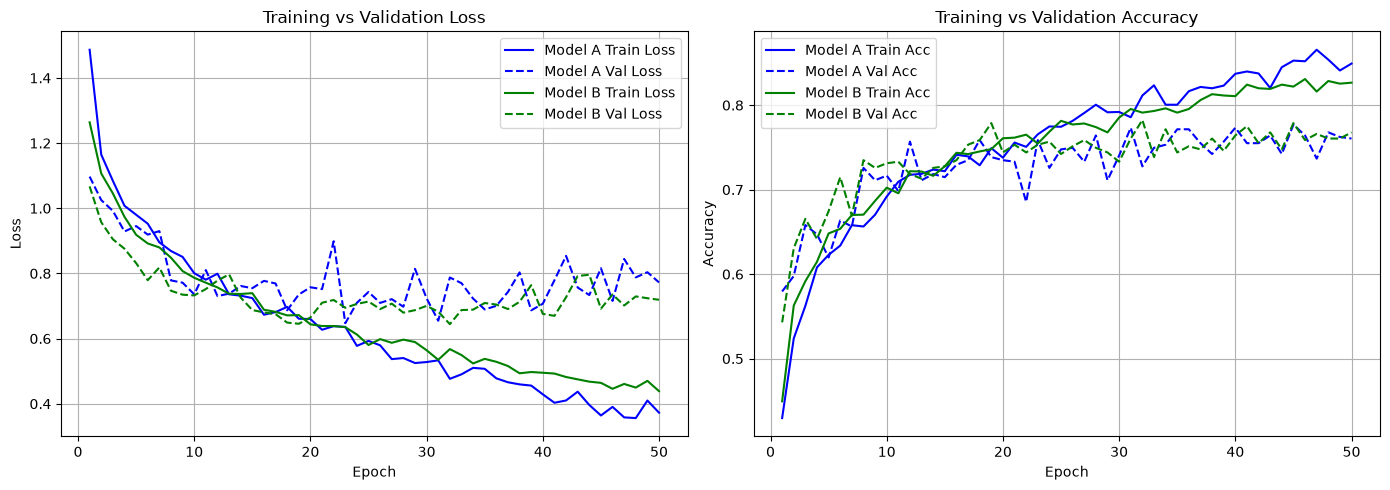


Metric                         | Model A (Standard) | Model B (Lightweight)
Total Parameters               | 1,143,045          | 41,413            
Disk Size (KB)                 | 4475.49            | 174.30            
Time / Epoch (s)               | 3.850              | 3.371             
Test Accuracy                  | 76.62            % | 74.28            %
Model parameters successfully saved to c:\Users\Sithum Peiris\Documents\GitHub\CNN-to-perform-classification\saved_models!


In [5]:
import os
import sys
import time
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np

# Add project root to sys.path so 'models' and 'utils' imports work cleanly
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
if PROJECT_ROOT not in sys.path:
    sys.path.append(PROJECT_ROOT)

from models.model_a import ModelA
from models.model_b import ModelB

# ---------------------------------------------------------
# 1. Device Setup & Data Loaders
# ---------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Preprocessing pipeline
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

TRAIN_DIR = os.path.join(PROJECT_ROOT, "data", "train")
VAL_DIR = os.path.join(PROJECT_ROOT, "data", "val")
TEST_DIR = os.path.join(PROJECT_ROOT, "data", "test")

# Training augmentation
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.10
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Validation and test: NO random augmentation
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_dataset = datasets.ImageFolder(
    root=TRAIN_DIR, transform=train_transform
)
val_dataset = datasets.ImageFolder(
    root=VAL_DIR, transform=eval_transform
)
test_dataset = datasets.ImageFolder(
    root=TEST_DIR, transform=eval_transform
)

train_loader = DataLoader(
    train_dataset, batch_size=32, shuffle=True
)
val_loader = DataLoader(
    val_dataset, batch_size=32, shuffle=False
)
test_loader = DataLoader(
    test_dataset, batch_size=32, shuffle=False
)

# ---------------------------------------------------------
# 2. Training Loop Function
# ---------------------------------------------------------
def train_and_validate(model, train_loader, val_loader, criterion, optimizer, epochs=50):
    model.to(device)
    train_losses, val_losses = [], []
    train_accs, val_accs = [], []
    
    start_time = time.time()

    for epoch in range(epochs):
        # Training Phase
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        epoch_train_loss = running_loss / len(train_dataset)
        epoch_train_acc = correct / total
        train_losses.append(epoch_train_loss)
        train_accs.append(epoch_train_acc)

        # Validation Phase
        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * inputs.size(0)
                _, predicted = torch.max(outputs, 1)
                val_total += labels.size(0)
                val_correct += (predicted == labels).sum().item()

        epoch_val_loss = val_loss / len(val_dataset)
        epoch_val_acc = val_correct / val_total
        val_losses.append(epoch_val_loss)
        val_accs.append(epoch_val_acc)

        print(f"Epoch [{epoch+1:02d}/{epochs:02d}] - "
              f"Train Loss: {epoch_train_loss:.4f}, Train Acc: {epoch_train_acc:.4f} | "
              f"Val Loss: {epoch_val_loss:.4f}, Val Acc: {epoch_val_acc:.4f}")

    total_time = time.time() - start_time
    avg_epoch_time = total_time / epochs
    
    return {
        'train_losses': train_losses,
        'val_losses': val_losses,
        'train_accs': train_accs,
        'val_accs': val_accs,
        'avg_epoch_time': avg_epoch_time
    }

# ---------------------------------------------------------
# 3. Test Evaluation Function
# ---------------------------------------------------------
def evaluate_test(model, test_loader):
    model.eval()
    model.to(device)
    correct, total = 0, 0
    all_preds, all_labels = [], []
    
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
            
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            
    test_accuracy = correct / total
    return test_accuracy, np.array(all_preds), np.array(all_labels)

# Helper function to compute file size on disk in KB
def get_model_disk_size_kb(model, filename="temp_model.pth"):
    torch.save(model.state_dict(), filename)
    size_bytes = os.path.getsize(filename)
    os.remove(filename)
    return size_bytes / 1024.0

# ---------------------------------------------------------
# 4. Train Model A & Model B (Adam Optimizer)
# ---------------------------------------------------------
criterion = nn.CrossEntropyLoss()

print("\n==========================================")
print("       TRAINING MODEL A (Standard CNN)")
print("==========================================")
model_a = ModelA(num_classes=5)
optimizer_a = optim.Adam(
    model_a.parameters(),
    lr=0.001,
    weight_decay=1e-4
)
history_a = train_and_validate(model_a, train_loader, val_loader, criterion, optimizer_a, epochs=50)
test_acc_a, _, _ = evaluate_test(model_a, test_loader)
params_a = sum(p.numel() for p in model_a.parameters() if p.requires_grad)
disk_size_a = get_model_disk_size_kb(model_a)

print("\n==========================================")
print("   TRAINING MODEL B (Lightweight Depthwise)")
print("==========================================")
model_b = ModelB(num_classes=5)
optimizer_b = optim.Adam(
    model_b.parameters(),
    lr=0.001,
    weight_decay=1e-4
)
history_b = train_and_validate(model_b, train_loader, val_loader, criterion, optimizer_b, epochs=50)
test_acc_b, _, _ = evaluate_test(model_b, test_loader)
params_b = sum(p.numel() for p in model_b.parameters() if p.requires_grad)
disk_size_b = get_model_disk_size_kb(model_b)

# ---------------------------------------------------------
# 5. Plot Loss & Accuracy Curves (Section 4 Requirement)
# ---------------------------------------------------------

# ---------------------------------------------------------
# 5. Plot Loss & Accuracy Curves
# ---------------------------------------------------------
fig, axs = plt.subplots(1, 2, figsize=(14, 5))

epochs_a = range(1, len(history_a['train_losses']) + 1)
epochs_b = range(1, len(history_b['train_losses']) + 1)

# Loss Plot
axs[0].plot(epochs_a, history_a['train_losses'],
            'b-', label='Model A Train Loss')
axs[0].plot(epochs_a, history_a['val_losses'],
            'b--', label='Model A Val Loss')
axs[0].plot(epochs_b, history_b['train_losses'],
            'g-', label='Model B Train Loss')
axs[0].plot(epochs_b, history_b['val_losses'],
            'g--', label='Model B Val Loss')

axs[0].set_title('Training vs Validation Loss')
axs[0].set_xlabel('Epoch')
axs[0].set_ylabel('Loss')
axs[0].legend()
axs[0].grid(True)

# Accuracy Plot
axs[1].plot(epochs_a, history_a['train_accs'],
            'b-', label='Model A Train Acc')
axs[1].plot(epochs_a, history_a['val_accs'],
            'b--', label='Model A Val Acc')
axs[1].plot(epochs_b, history_b['train_accs'],
            'g-', label='Model B Train Acc')
axs[1].plot(epochs_b, history_b['val_accs'],
            'g--', label='Model B Val Acc')

axs[1].set_title('Training vs Validation Accuracy')
axs[1].set_xlabel('Epoch')
axs[1].set_ylabel('Accuracy')
axs[1].legend()
axs[1].grid(True)

plt.tight_layout()
plt.savefig('custom_models_training_curves.png', dpi=300)
plt.show()


# ---------------------------------------------------------
# 6. Summary Comparison Table (Section 4 Requirement)
# ---------------------------------------------------------
print("\n" + "="*70)
print(f"{'Metric':<30} | {'Model A (Standard)':<18} | {'Model B (Lightweight)':<18}")
print("="*70)
print(f"{'Total Parameters':<30} | {params_a:<18,} | {params_b:<18,}")
print(f"{'Disk Size (KB)':<30} | {disk_size_a:<18.2f} | {disk_size_b:<18.2f}")
print(f"{'Time / Epoch (s)':<30} | {history_a['avg_epoch_time']:<18.3f} | {history_b['avg_epoch_time']:<18.3f}")
print(f"{'Test Accuracy':<30} | {test_acc_a*100:<17.2f}% | {test_acc_b*100:<17.2f}%")
print("="*70)

# 1. Create directory for weights
weights_dir = os.path.join(PROJECT_ROOT, "saved_models")
os.makedirs(weights_dir, exist_ok=True)

# 2. Save state dictionaries
torch.save(model_a.state_dict(), os.path.join(weights_dir, "model_a_weights.pth"))
torch.save(model_b.state_dict(), os.path.join(weights_dir, "model_b_weights.pth"))

print(f"Model parameters successfully saved to {weights_dir}!")

Using device: cuda

Class mapping: {'daisy': 0, 'dandelion': 1, 'rose': 2, 'sunflower': 3, 'tulip': 4}
Training images:   2567
Validation images: 547
Test images:       556

TRAINING MODEL A (Standard CNN)
Epoch [01/50] | Train Loss: 1.4581 | Val Loss: 1.1960 | Train Acc: 0.4422 | Val Acc: 0.4936 | LR: 0.001000
Epoch [02/50] | Train Loss: 1.1477 | Val Loss: 0.9862 | Train Acc: 0.5356 | Val Acc: 0.6069 | LR: 0.001000
Epoch [03/50] | Train Loss: 1.0587 | Val Loss: 1.0181 | Train Acc: 0.5719 | Val Acc: 0.6143 | LR: 0.001000
Epoch [04/50] | Train Loss: 0.9985 | Val Loss: 0.8902 | Train Acc: 0.6062 | Val Acc: 0.6600 | LR: 0.001000
Epoch [05/50] | Train Loss: 0.9441 | Val Loss: 0.9627 | Train Acc: 0.6299 | Val Acc: 0.6435 | LR: 0.001000
Epoch [06/50] | Train Loss: 0.9441 | Val Loss: 0.8591 | Train Acc: 0.6280 | Val Acc: 0.6764 | LR: 0.001000
Epoch [07/50] | Train Loss: 0.9095 | Val Loss: 0.7640 | Train Acc: 0.6494 | Val Acc: 0.7203 | LR: 0.001000
Epoch [08/50] | Train Loss: 0.8574 | Val Loss

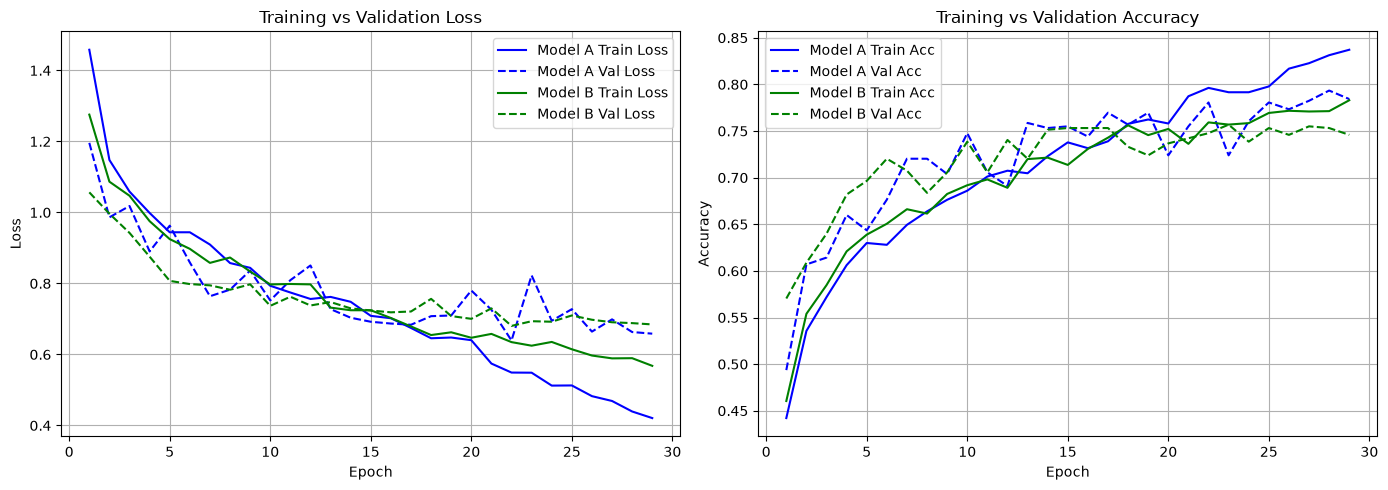


Training curves saved to: c:\Users\Sithum Peiris\Documents\GitHub\CNN-to-perform-classification\custom_models_training_curves.png

Metric                         | Model A (Standard)     | Model B (Lightweight) 
Total Parameters               | 1,143,045              | 41,413                
Disk Size (KB)                 | 4475.55                | 174.37                
Time / Epoch (s)               | 3.423                  | 3.392                 
Epochs Trained                 | 29                     | 29                    
Best Epoch                     | 22                     | 22                    
Best Validation Loss           | 0.6393                 | 0.6804                
Test Accuracy                  | 74.46                % | 70.50                %

Best Model A checkpoint saved in: c:\Users\Sithum Peiris\Documents\GitHub\CNN-to-perform-classification\saved_models\model_a_weights.pth
Best Model B checkpoint saved in: c:\Users\Sithum Peiris\Documents\GitHub\CNN-to-p

In [6]:

import os
import sys
import time
import copy
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np

# ---------------------------------------------------------
# 1. Project and Device Setup
# ---------------------------------------------------------

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))

if PROJECT_ROOT not in sys.path:
    sys.path.append(PROJECT_ROOT)

from models.model_a import ModelA
from models.model_b import ModelB

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# ---------------------------------------------------------
# 2. Dataset Paths
# ---------------------------------------------------------

TRAIN_DIR = os.path.join(PROJECT_ROOT, "data", "train")
VAL_DIR = os.path.join(PROJECT_ROOT, "data", "val")
TEST_DIR = os.path.join(PROJECT_ROOT, "data", "test")

# ---------------------------------------------------------
# 3. Data Transformations
# ---------------------------------------------------------

# Augmentation is applied only to training images.
# Remove horizontal flipping if orientation affects class labels.

train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.10
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Validation and test data must remain unchanged.
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_dataset = datasets.ImageFolder(
    root=TRAIN_DIR,
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    root=VAL_DIR,
    transform=eval_transform
)

test_dataset = datasets.ImageFolder(
    root=TEST_DIR,
    transform=eval_transform
)

# Check class consistency
print("\nClass mapping:", train_dataset.class_to_idx)

assert train_dataset.class_to_idx == val_dataset.class_to_idx, \
    "Training and validation class mappings do not match!"

assert train_dataset.class_to_idx == test_dataset.class_to_idx, \
    "Training and test class mappings do not match!"

assert len(train_dataset.classes) == 5, \
    "Expected exactly 5 classes."

# Data loaders
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

print(f"Training images:   {len(train_dataset)}")
print(f"Validation images: {len(val_dataset)}")
print(f"Test images:       {len(test_dataset)}")

# ---------------------------------------------------------
# 4. Training and Validation Function
# ---------------------------------------------------------

def train_and_validate(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    epochs=50,
    patience=7
):
    model.to(device)

    train_losses = []
    val_losses = []
    train_accs = []
    val_accs = []

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    )

    best_val_loss = float("inf")
    best_state = copy.deepcopy(model.state_dict())
    best_epoch = 0
    epochs_without_improvement = 0

    start_time = time.time()

    for epoch in range(epochs):

        # ---------------- TRAINING ----------------
        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for inputs, labels in train_loader:

            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)

            predicted = outputs.argmax(dim=1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        epoch_train_loss = (
            running_loss / len(train_loader.dataset)
        )

        epoch_train_acc = correct / total

        train_losses.append(epoch_train_loss)
        train_accs.append(epoch_train_acc)

        # ---------------- VALIDATION ----------------
        model.eval()

        val_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():

            for inputs, labels in val_loader:

                inputs = inputs.to(device)
                labels = labels.to(device)

                outputs = model(inputs)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * inputs.size(0)

                predicted = outputs.argmax(dim=1)

                val_total += labels.size(0)
                val_correct += (
                    predicted == labels
                ).sum().item()

        epoch_val_loss = (
            val_loss / len(val_loader.dataset)
        )

        epoch_val_acc = val_correct / val_total

        val_losses.append(epoch_val_loss)
        val_accs.append(epoch_val_acc)

        # ---------------- LEARNING RATE ----------------
        scheduler.step(epoch_val_loss)

        current_lr = optimizer.param_groups[0]["lr"]

        # ---------------- BEST CHECKPOINT ----------------
        # A tiny improvement is counted to avoid stopping
        # merely because validation loss changes very little.

        if epoch_val_loss < best_val_loss - 1e-4:

            best_val_loss = epoch_val_loss

            best_state = copy.deepcopy(
                model.state_dict()
            )

            best_epoch = epoch + 1
            epochs_without_improvement = 0

        else:
            epochs_without_improvement += 1

        # ---------------- LOGGING ----------------
        print(
            f"Epoch [{epoch + 1:02d}/{epochs:02d}] | "
            f"Train Loss: {epoch_train_loss:.4f} | "
            f"Val Loss: {epoch_val_loss:.4f} | "
            f"Train Acc: {epoch_train_acc:.4f} | "
            f"Val Acc: {epoch_val_acc:.4f} | "
            f"LR: {current_lr:.6f}"
        )

        # ---------------- EARLY STOPPING ----------------
        if epochs_without_improvement >= patience:

            print(
                f"\nEarly stopping at epoch {epoch + 1}."
            )
            print(
                f"Best validation loss: {best_val_loss:.4f}"
            )
            print(
                f"Best epoch: {best_epoch}"
            )
            break

    # Restore the weights from the best validation epoch.
    model.load_state_dict(best_state)

    total_time = time.time() - start_time
    actual_epochs = len(train_losses)

    avg_epoch_time = total_time / actual_epochs

    return {
        "train_losses": train_losses,
        "val_losses": val_losses,
        "train_accs": train_accs,
        "val_accs": val_accs,
        "avg_epoch_time": avg_epoch_time,
        "best_val_loss": best_val_loss,
        "best_epoch": best_epoch,
        "epochs_trained": actual_epochs
    }


# ---------------------------------------------------------
# 5. Test Evaluation Function
# ---------------------------------------------------------

def evaluate_test(model, test_loader):

    model.to(device)
    model.eval()

    correct = 0
    total = 0

    all_preds = []
    all_labels = []

    with torch.no_grad():

        for inputs, labels in test_loader:

            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            predicted = outputs.argmax(dim=1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

            all_preds.extend(
                predicted.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    test_accuracy = correct / total

    return (
        test_accuracy,
        np.array(all_preds),
        np.array(all_labels)
    )


# ---------------------------------------------------------
# 6. Model Size Calculation
# ---------------------------------------------------------

def get_model_disk_size_kb(model, filename):

    torch.save(model.state_dict(), filename)

    size_bytes = os.path.getsize(filename)

    os.remove(filename)

    return size_bytes / 1024.0


# ---------------------------------------------------------
# 7. Loss Function and Output Directory
# ---------------------------------------------------------

criterion = nn.CrossEntropyLoss()

weights_dir = os.path.join(
    PROJECT_ROOT, "saved_models"
)

os.makedirs(weights_dir, exist_ok=True)


# ---------------------------------------------------------
# 8. Train Model A
# ---------------------------------------------------------

print("\n" + "=" * 60)
print("TRAINING MODEL A (Standard CNN)")
print("=" * 60)

model_a = ModelA(num_classes=5)

optimizer_a = optim.Adam(
    model_a.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

history_a = train_and_validate(
    model_a,
    train_loader,
    val_loader,
    criterion,
    optimizer_a,
    epochs=50,
    patience=7
)

# Save the best validation checkpoint.
torch.save(
    model_a.state_dict(),
    os.path.join(weights_dir, "model_a_weights.pth")
)

params_a = sum(
    p.numel()
    for p in model_a.parameters()
    if p.requires_grad
)

disk_size_a = get_model_disk_size_kb(
    model_a,
    os.path.join(weights_dir, "temp_model_a.pth")
)


# ---------------------------------------------------------
# 9. Train Model B
# ---------------------------------------------------------

print("\n" + "=" * 60)
print("TRAINING MODEL B (Lightweight Depthwise CNN)")
print("=" * 60)

model_b = ModelB(num_classes=5)

optimizer_b = optim.Adam(
    model_b.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

history_b = train_and_validate(
    model_b,
    train_loader,
    val_loader,
    criterion,
    optimizer_b,
    epochs=50,
    patience=7
)

# Save the best validation checkpoint.
torch.save(
    model_b.state_dict(),
    os.path.join(weights_dir, "model_b_weights.pth")
)

params_b = sum(
    p.numel()
    for p in model_b.parameters()
    if p.requires_grad
)

disk_size_b = get_model_disk_size_kb(
    model_b,
    os.path.join(weights_dir, "temp_model_b.pth")
)


# ---------------------------------------------------------
# 10. Final Test Evaluation
# ---------------------------------------------------------

# Evaluate each selected best checkpoint on the test set.
test_acc_a, test_preds_a, test_labels_a = evaluate_test(
    model_a, test_loader
)

test_acc_b, test_preds_b, test_labels_b = evaluate_test(
    model_b, test_loader
)


# ---------------------------------------------------------
# 11. Plot Training and Validation Curves
# ---------------------------------------------------------

fig, axs = plt.subplots(1, 2, figsize=(14, 5))

epochs_a = range(
    1, len(history_a["train_losses"]) + 1
)

epochs_b = range(
    1, len(history_b["train_losses"]) + 1
)

# Loss curves
axs[0].plot(
    epochs_a, history_a["train_losses"],
    "b-", label="Model A Train Loss"
)

axs[0].plot(
    epochs_a, history_a["val_losses"],
    "b--", label="Model A Val Loss"
)

axs[0].plot(
    epochs_b, history_b["train_losses"],
    "g-", label="Model B Train Loss"
)

axs[0].plot(
    epochs_b, history_b["val_losses"],
    "g--", label="Model B Val Loss"
)

axs[0].set_title("Training vs Validation Loss")
axs[0].set_xlabel("Epoch")
axs[0].set_ylabel("Loss")
axs[0].legend()
axs[0].grid(True)

# Accuracy curves
axs[1].plot(
    epochs_a, history_a["train_accs"],
    "b-", label="Model A Train Acc"
)

axs[1].plot(
    epochs_a, history_a["val_accs"],
    "b--", label="Model A Val Acc"
)

axs[1].plot(
    epochs_b, history_b["train_accs"],
    "g-", label="Model B Train Acc"
)

axs[1].plot(
    epochs_b, history_b["val_accs"],
    "g--", label="Model B Val Acc"
)

axs[1].set_title("Training vs Validation Accuracy")
axs[1].set_xlabel("Epoch")
axs[1].set_ylabel("Accuracy")
axs[1].legend()
axs[1].grid(True)

plt.tight_layout()

plot_path = os.path.join(
    PROJECT_ROOT,
    "custom_models_training_curves.png"
)

plt.savefig(plot_path, dpi=300)
plt.show()

print(f"\nTraining curves saved to: {plot_path}")


# ---------------------------------------------------------
# 12. Summary Comparison Table
# ---------------------------------------------------------

print("\n" + "=" * 85)

print(
    f"{'Metric':<30} | "
    f"{'Model A (Standard)':<22} | "
    f"{'Model B (Lightweight)':<22}"
)

print("=" * 85)

print(
    f"{'Total Parameters':<30} | "
    f"{params_a:<22,} | "
    f"{params_b:<22,}"
)

print(
    f"{'Disk Size (KB)':<30} | "
    f"{disk_size_a:<22.2f} | "
    f"{disk_size_b:<22.2f}"
)

print(
    f"{'Time / Epoch (s)':<30} | "
    f"{history_a['avg_epoch_time']:<22.3f} | "
    f"{history_b['avg_epoch_time']:<22.3f}"
)

print(
    f"{'Epochs Trained':<30} | "
    f"{history_a['epochs_trained']:<22} | "
    f"{history_b['epochs_trained']:<22}"
)

print(
    f"{'Best Epoch':<30} | "
    f"{history_a['best_epoch']:<22} | "
    f"{history_b['best_epoch']:<22}"
)

print(
    f"{'Best Validation Loss':<30} | "
    f"{history_a['best_val_loss']:<22.4f} | "
    f"{history_b['best_val_loss']:<22.4f}"
)

print(
    f"{'Test Accuracy':<30} | "
    f"{test_acc_a * 100:<21.2f}% | "
    f"{test_acc_b * 100:<21.2f}%"
)

print("=" * 85)

print(
    f"\nBest Model A checkpoint saved in: "
    f"{os.path.join(weights_dir, 'model_a_weights.pth')}"
)

print(
    f"Best Model B checkpoint saved in: "
    f"{os.path.join(weights_dir, 'model_b_weights.pth')}"
)

print("\nTraining and evaluation completed!")


Loaded Model A weights successfully.
Loaded Model B weights successfully.
Generating class activation templates for Model A...
Generating class activation templates for Model B...


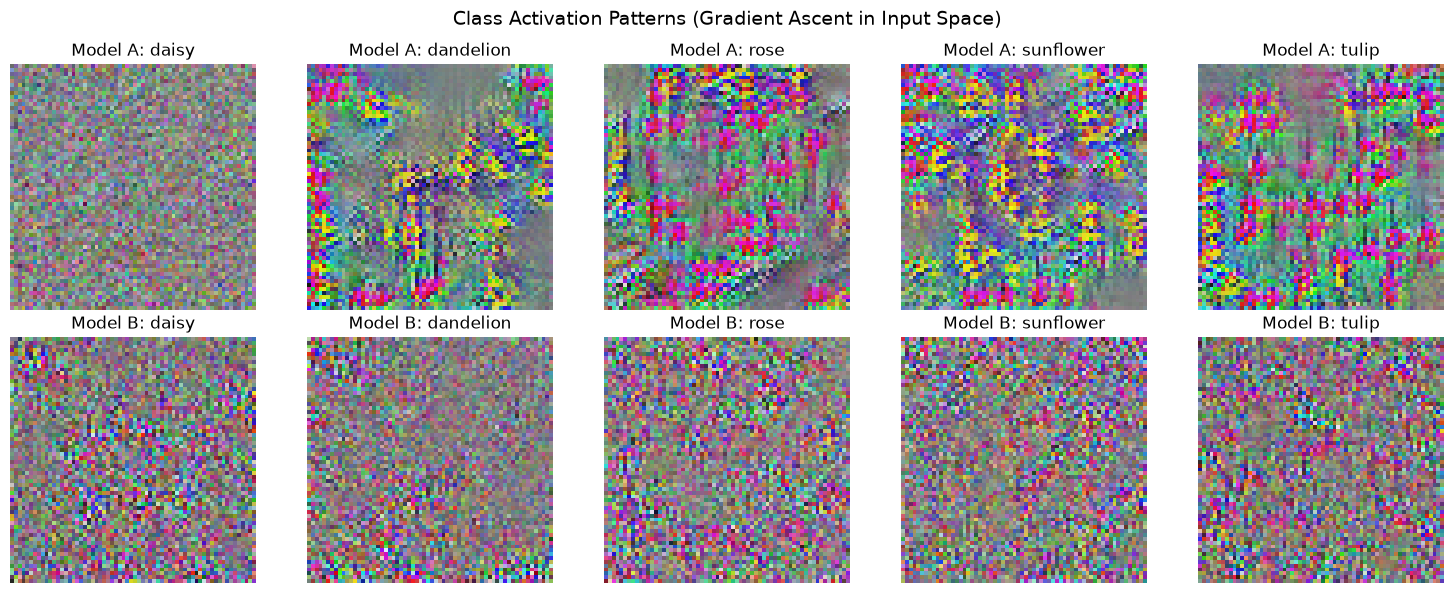

In [3]:
import os
import sys
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

# Path resolution so models can be imported from any location
CURRENT_DIR = os.path.dirname(os.path.abspath(__file__)) if "__file__" in locals() else os.getcwd()
PROJECT_ROOT = os.path.abspath(os.path.join(CURRENT_DIR, ".."))

if PROJECT_ROOT not in sys.path:
    sys.path.append(PROJECT_ROOT)

from models.model_a import ModelA
from models.model_b import ModelB

def generate_class_template(model, target_class_idx, steps=300, lr=0.05, device='cpu'):
    """
    Performs Gradient Ascent starting from random noise to generate an image
    that maximally activates a target class in the given model.
    """
    model.eval()
    model.to(device)

    # Start with random noise image (1, 3, 64, 64)
    input_img = torch.randn(1, 3, 64, 64, device=device, requires_grad=True)
    optimizer = torch.optim.Adam([input_img], lr=lr)

    for step in range(steps):
        optimizer.zero_grad()
        output = model(input_img)
        
        # Loss is negative logits for the target class (gradient ascent minimizes this)
        loss = -output[0, target_class_idx]
        loss.backward()
        optimizer.step()

    # Post-process tensor back to RGB viewable image [0, 1]
    img = input_img.squeeze(0).detach().cpu().numpy()
    img = np.transpose(img, (1, 2, 0))
    img = (img - img.min()) / (img.max() - img.min() + 1e-8)  # Normalize
    return img

def show_both_models_class_templates(model_a, model_b, class_names=['daisy', 'dandelion', 'rose', 'sunflower', 'tulip'], device='cpu'):
    """
    Generates and plots class activation templates for Model A and Model B side-by-side.
    """
    fig, axs = plt.subplots(2, 5, figsize=(15, 6))

    print("Generating class activation templates for Model A...")
    for idx, name in enumerate(class_names):
        template_a = generate_class_template(model_a, target_class_idx=idx, device=device)
        axs[0, idx].imshow(template_a)
        axs[0, idx].set_title(f"Model A: {name}")
        axs[0, idx].axis('off')

    print("Generating class activation templates for Model B...")
    for idx, name in enumerate(class_names):
        template_b = generate_class_template(model_b, target_class_idx=idx, device=device)
        axs[1, idx].imshow(template_b)
        axs[1, idx].set_title(f"Model B: {name}")
        axs[1, idx].axis('off')

    plt.suptitle("Class Activation Patterns (Gradient Ascent in Input Space)", fontsize=14)
    plt.tight_layout()
    plt.savefig('class_activation_templates.png')
    plt.show()

# --- Execution Block ---
if __name__ == "__main__":
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # 1. Instantiate models
    model_a = ModelA(num_classes=5)
    model_b = ModelB(num_classes=5)

    # 2. Locate saved weight files
    weights_a_path = os.path.join(PROJECT_ROOT, "saved_models", "model_a_weights.pth")
    weights_b_path = os.path.join(PROJECT_ROOT, "saved_models", "model_b_weights.pth")

    # 3. Load saved weights
    if os.path.exists(weights_a_path):
        model_a.load_state_dict(torch.load(weights_a_path, map_location=device))
        print("Loaded Model A weights successfully.")
    else:
        print(f"Warning: Model A weights not found at '{weights_a_path}'. Using untrained weights.")

    if os.path.exists(weights_b_path):
        model_b.load_state_dict(torch.load(weights_b_path, map_location=device))
        print("Loaded Model B weights successfully.")
    else:
        print(f"Warning: Model B weights not found at '{weights_b_path}'. Using untrained weights.")

    # 4. Generate and display templates
    show_both_models_class_templates(model_a, model_b, device=device)